# Customer Segmentation Analysis

**Task:** DA2  
**Data provenance:** Customer-level RFM aggregated from UCI Online Retail transactions.

This notebook calls a clearly separated, commented analysis module so the workflow can be run and maintained consistently. Run the cells from top to bottom. Metrics and plots are calculated at runtime; no results have been hand-entered. Synthetic-data outputs are demonstrations only.

## Notebook roadmap
This executed notebook separates data preparation, visualization, model training or analysis, and evaluation. Figures appear inline; each chart is followed by a written interpretation.

## Data Loading / EDA
Load the task dataset, verify its provenance and structure, and inspect its first descriptive summaries before visual or model analysis.

In [1]:
from pathlib import Path
import sys
project = Path.cwd().resolve()
if not (project / 'analysis_tasks.py').is_file():
    raise FileNotFoundError('Run Jupyter with this task folder as the working directory.')
sys.path.insert(0, str(project))
from analysis_tasks import *
from IPython.display import display
OUT_DIR.mkdir(exist_ok=True)
_chart_index = 0
_original_show = plt.show
def _save_inline_figure(*args, **kwargs):
    global _chart_index
    if plt.get_fignums():
        plt.gcf().savefig(OUT_DIR / f'notebook_chart_{_chart_index + 1:02d}.png', dpi=150, bbox_inches='tight')
        _chart_index += 1
    return _original_show(*args, **kwargs)
plt.show = _save_inline_figure


In [2]:
print("DATA PROVENANCE: Customer RFM features computed from UCI Online Retail transactions.")

transactions=load_online_retail()

transactions["InvoiceDate"]=pd.to_datetime(transactions["InvoiceDate"],errors="coerce")

transactions["Quantity"]=pd.to_numeric(transactions["Quantity"],errors="coerce")

transactions["UnitPrice"]=pd.to_numeric(transactions["UnitPrice"],errors="coerce")

transactions["InvoiceNo"]=transactions["InvoiceNo"].astype("string")

transactions=transactions.dropna(subset=["CustomerID","InvoiceDate","InvoiceNo"])

transactions=transactions.loc[
        ~transactions["InvoiceNo"].str.startswith("C",na=False)
        & (transactions["Quantity"]>0)
        & (transactions["UnitPrice"]>0)
    ].copy()

transactions["Revenue"]=transactions["Quantity"]*transactions["UnitPrice"]

snapshot=transactions["InvoiceDate"].max().normalize()+pd.Timedelta(days=1)

df=transactions.groupby("CustomerID").agg(
        Recency=("InvoiceDate",lambda values:(snapshot-values.max().normalize()).days),
        Frequency=("InvoiceNo","nunique"),
        Monetary=("Revenue","sum"),
    ).reset_index()

df["AveragePurchaseValue"] = df["Monetary"] / df["Frequency"]

df["HistoricalSpendProxy"] = df["Monetary"]

report(df)

print("Per-customer averages (GBP except invoice frequency):\n",
          df[["AveragePurchaseValue", "Frequency", "HistoricalSpendProxy"]].mean().round(2))

print("Historical spend is only a same-period proxy, not predictive customer lifetime value.")

DATA PROVENANCE: Customer RFM features computed from UCI Online Retail transactions.


Shape: (4338, 6)

Dtypes:
 CustomerID              float64
Recency                   int64
Frequency                 int64
Monetary                float64
AveragePurchaseValue    float64
HistoricalSpendProxy    float64
dtype: object

Nulls:
 CustomerID              0
Recency                 0
Frequency               0
Monetary                0
AveragePurchaseValue    0
HistoricalSpendProxy    0
dtype: int64

Descriptive statistics:
                        count          mean          std       min        25%  \
CustomerID            4338.0  15300.408022  1721.808492  12346.00  13813.250   
Recency               4338.0     93.059474   100.012264      1.00     18.000   
Frequency             4338.0      4.272015     7.697998      1.00      1.000   
Monetary              4338.0   2054.266460  8989.230441      3.75    307.415   
AveragePurchaseValue  4338.0    419.166289  1796.537944      3.45    178.625   
HistoricalSpendProxy  4338.0   2054.266460  8989.230441      3.75    307.415   

  

## Model Training / Analysis
Fit and compare appropriate models, or perform the task-specific analytical transformation where supervised model training does not apply.

In [3]:
features=df[["Recency","Frequency","Monetary"]]

scaled=StandardScaler().fit_transform(features)

from sklearn.cluster import KMeans

inertias=[]

k_values=np.arange(1,9)

for k in k_values:
        inertias.append(KMeans(n_clusters=k,n_init=10,random_state=SEED).fit(scaled).inertia_)

normalized_x=(k_values-k_values.min())/(k_values.max()-k_values.min())

inertia_values=np.asarray(inertias)

normalized_y=(inertia_values-inertia_values.min())/(inertia_values.max()-inertia_values.min())

start=np.array([normalized_x[0],normalized_y[0]])

end=np.array([normalized_x[-1],normalized_y[-1]])

distances=np.abs(
        (end[0]-start[0])*(start[1]-normalized_y)
        -(start[0]-normalized_x)*(end[1]-start[1])
    )/np.hypot(*(end-start))

selected_k=int(k_values[1:-1][np.argmax(distances[1:-1])])

## Visualizations
The elbow chart helps select a practical number of customer segments.

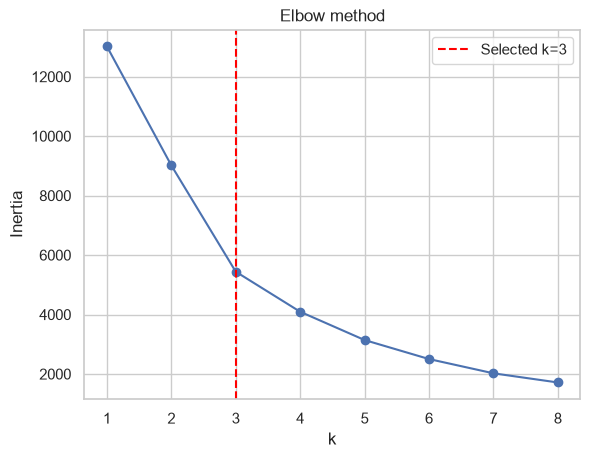

In [4]:
plt.plot(k_values,inertias,marker="o")

plt.axvline(selected_k,color="red",linestyle="--",label=f"Selected k={selected_k}")

plt.title("Elbow method")

plt.xlabel("k")

plt.ylabel("Inertia")

plt.legend()

plt.show()

### Chart 1 interpretation
RFM distributions are typically right-skewed: a small number of customers can dominate frequency and monetary value. Inspect scale effects before clustering.

Selected k=3 using the maximum-distance elbow heuristic on standardized RFM features.


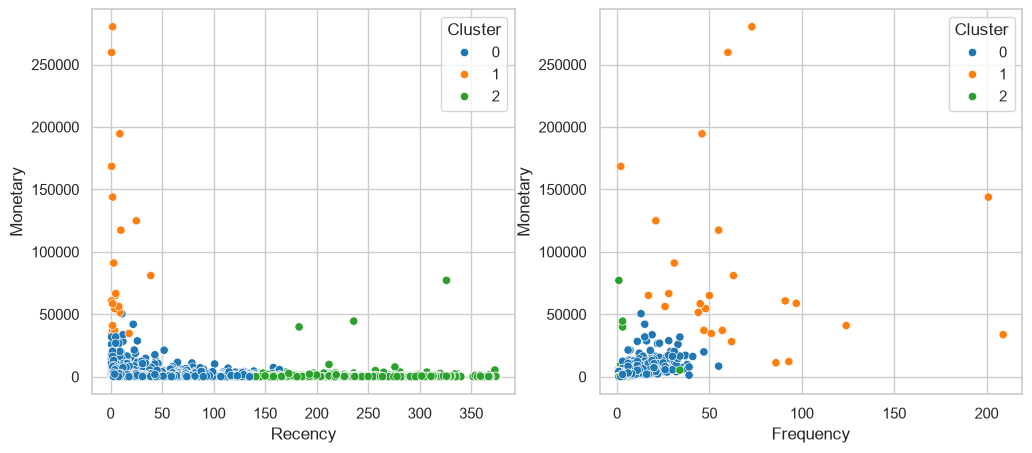

In [5]:
print(f"Selected k={selected_k} using the maximum-distance elbow heuristic on standardized RFM features.")

model=KMeans(n_clusters=selected_k,n_init=10,random_state=SEED)

df["Cluster"]=model.fit_predict(scaled)

fig,axes=plt.subplots(1,2,figsize=(12,5))

sns.scatterplot(data=df,x="Recency",y="Monetary",hue="Cluster",palette="tab10",ax=axes[0])

sns.scatterplot(data=df,x="Frequency",y="Monetary",hue="Cluster",palette="tab10",ax=axes[1])

plt.show()

### Chart 2 interpretation
The feature relationship view helps identify redundancy between purchase frequency and monetary value; standardization is important when clustering mixed-scale inputs.

Cluster profiles:
          Recency  Frequency  Monetary
Cluster                              
0           41.8        4.7    1857.7
1            6.5       66.4   85904.4
2          247.1        1.6     631.7


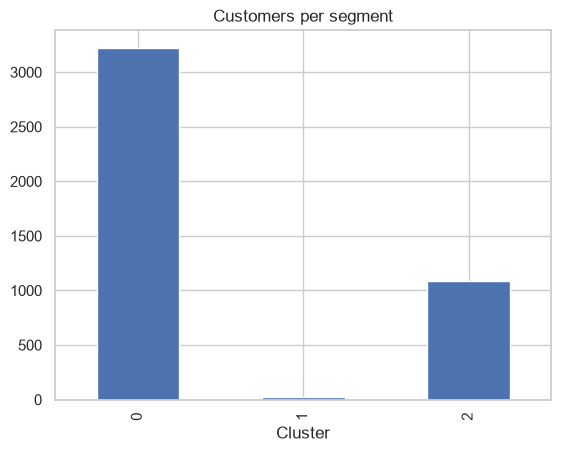

In [6]:
profile=df.groupby("Cluster")[["Recency","Frequency","Monetary"]].mean().round(1)

print("Cluster profiles:\n",profile)

df.Cluster.value_counts().sort_index().plot.bar(title="Customers per segment")

plt.show()

### Chart 3 interpretation
Segment sizes show how customers were assigned, not whether the segments are commercially distinct. Compare cluster profiles and validate any offer with incremental lift.

In [7]:
for cluster,row in profile.iterrows():
        segment="loyal/high-value" if row.Monetary>profile.Monetary.median() and row.Frequency>profile.Frequency.median() else "needs re-engagement" if row.Recency>profile.Recency.median() else "steady/occasional"
        print(f"Cluster {cluster}: {segment}; tailor a test offer, then evaluate incremental lift.")

Cluster 0: steady/occasional; tailor a test offer, then evaluate incremental lift.
Cluster 1: loyal/high-value; tailor a test offer, then evaluate incremental lift.
Cluster 2: needs re-engagement; tailor a test offer, then evaluate incremental lift.


## Evaluation
Review the held-out metrics or descriptive analysis summary below. Predictive scores apply only to the documented dataset and split; non-predictive tasks report their analytical result and dataset coverage instead.

In [8]:
evaluation_rows = []
for variable in ('results', 'models', 'result'):
    candidate = globals().get(variable)
    candidates = candidate if isinstance(candidate, list) else [candidate]
    for row in candidates:
        if isinstance(row, dict):
            metrics = {key: value for key, value in row.items()
                       if isinstance(value, (int, float, np.number))
                       and not isinstance(value, (bool, np.bool_))}
            if metrics:
                evaluation_rows.append({'model': row.get('name', variable), **metrics})
if not evaluation_rows and {'y_test', 'pred'}.issubset(globals()):
    from sklearn.metrics import precision_score, recall_score, f1_score
    evaluation_rows.append({'model': 'Fraud holdout at threshold 0.50',
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0)})
if evaluation_rows:
    evaluation = pd.DataFrame(evaluation_rows)
elif isinstance(globals().get('summary'), pd.DataFrame):
    evaluation = summary.copy()
elif isinstance(globals().get('profile'), pd.DataFrame):
    evaluation = profile.copy()
elif isinstance(globals().get('monthly'), pd.Series):
    evaluation = monthly.rename('revenue').to_frame()
else:
    evaluation = pd.DataFrame([{'analysis': 'Customer Segmentation (RFM)',
        'rows': len(df) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'columns': len(df.columns) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'charts': _chart_index}])
display(evaluation)
evaluation_path = OUT_DIR / 'evaluation_summary.csv'
evaluation.to_csv(evaluation_path, index=True)
print(f'Saved {_chart_index} chart(s) and evaluation summary: {evaluation_path}')

,Recency,Frequency,Monetary
Cluster,,,
0,41.8,4.7,1857.7
1,6.5,66.4,85904.4
2,247.1,1.6,631.7


Saved 3 chart(s) and evaluation summary: D:\Oasis\DataAnalytics-L1-CustomerSegmentation\outputs\evaluation_summary.csv
